# Experiment 4 results: MNIST factor-ablation benchmark

Exploration notebook over the **committed summary tables** in `results/` —
one CSV per predeclared summary from `summarize.py`. No models are rerun;
the notebook stands alone on the CSVs. The run it reports is the
2026-11-03 full grid: 5 model seeds × 20 PHATE clusters × layers H1–H3 ×
top-5 factors × q ∈ {0.6, 0.7, 0.8, 0.9} (output-aware) and q = 0.8
(hidden-only): **600/600 fits, 141,000/141,000 interventions, zero
failures, zero exclusions** (run record: `results/full_run_report.txt`,
`paper/exp4.md` §E4.13).

Claims follow the pre-registration (`paper/exp4.md` §E4.12): influence-shaped,
never type claims; the model seed is the replicate (n = 5). The display
figures are rendered by `figures_exp4.py` (final cell).


In [1]:
import pathlib, json
import pandas as pd

HERE = pathlib.Path(".").resolve()
RESULTS = HERE / "results"

def load(name):
    return pd.read_csv(RESULTS / f"mnist_{name}.csv")

tables = {n: load(n) for n in [
    "prevalence", "lc_vs_random", "lc_vs_univariate", "support_density",
    "concordance", "oa_vs_ho", "effective_units", "tc_magnitude",
    "coverage", "tc_density_magnitude", "profile_cohorts", "profile_grid",
    "factor_assoc"]}
print({k: len(v) for k, v in tables.items()})

{'prevalence': 12, 'lc_vs_random': 72, 'lc_vs_univariate': 72, 'support_density': 12, 'concordance': 6, 'oa_vs_ho': 6, 'effective_units': 30, 'tc_magnitude': 12, 'coverage': 30, 'tc_density_magnitude': 6000, 'profile_cohorts': 18000, 'profile_grid': 15360, 'factor_assoc': 3000}


## Data integrity / coverage

In [2]:
cov = tables["coverage"]
print("coverage rows (seed × layer × condition):", len(cov))
print("clusters present (min):", int(cov.n_clusters_present.min()))
print("zero-effect rows:", int(cov.n_zero_effect.sum()))
print("factors per condition (min):", int(cov.n_factors_fit.min()))
print("per-seed test accuracies:")
import json
for p in sorted(RESULTS.glob("mnist_seed*_meta.json")):
    m = json.loads(p.read_text())
    print(f"  {p.stem}: acc={m['test_acc']:.4f} flag={m['acc_flag_below_97']} epochs={m['n_epochs_run']}")

coverage rows (seed × layer × condition): 30
clusters present (min): 20
zero-effect rows: 0
factors per condition (min): 5
per-seed test accuracies:
  mnist_seed5100_meta: acc=0.9864 flag=False epochs=84
  mnist_seed5101_meta: acc=0.9860 flag=False epochs=56
  mnist_seed5102_meta: acc=0.9864 flag=False epochs=83
  mnist_seed5103_meta: acc=0.9863 flag=False epochs=90
  mnist_seed5104_meta: acc=0.9862 flag=False epochs=94


**Coverage result:** 20/20 clusters and 5/5 usable (positive-TC) factors in
every (seed, layer, condition); no zero-effect rows, so the predeclared
zero-effect convention never fired. Denominators are the full grid.

## Reading 1 — Local CorEx vs matched random (prevalence + paired diffs)

In [3]:
tables["prevalence"]

,layer,threshold,prevalence,se,n_seeds,n_interventions
0,1,0.6,0.004,0.004000,5,500
1,1,0.7,0.032,0.005831,5,500
2,1,0.8,0.060,0.005477,5,500
3,1,0.9,0.058,0.009165,5,500
4,2,0.6,0.022,0.002000,5,500
5,2,0.7,0.076,0.007483,5,500
6,2,0.8,0.204,0.009274,5,500
7,2,0.9,0.376,0.021587,5,500
8,3,0.6,0.034,0.005099,5,500
9,3,0.7,0.080,0.004472,5,500


In [4]:
tables["lc_vs_random"].pivot_table(
    index=["metric"], columns=["layer", "threshold"], values="mean_diff")

layer              1                                       2            \
threshold        0.6       0.7       0.8       0.9       0.6       0.7   
metric                                                                   
D_input     0.109840  0.135815  0.163513  0.189767  0.232593  0.280738   
H_input    -0.083401 -0.107267 -0.135095 -0.167767 -0.184971 -0.232971   
T_max       0.011360  0.021449  0.040580  0.092850  0.017311  0.036299   
T_weighted  0.002276  0.003769  0.006518  0.014574  0.002461  0.004594   
U_max       0.010974  0.021191  0.040492  0.093060  0.017168  0.036201   
flip_rate   0.001964  0.003373  0.005897  0.012966  0.001863  0.003588   

layer                                  3                                
threshold        0.8       0.9       0.6       0.7       0.8       0.9  
metric                                                                  
D_input     0.336320  0.400999  0.126761  0.188241  0.280178  0.368089  
H_input    -0.295257 -0.375129 -0.104154 -0.157363 -0.241218 -0.334488  
T_max       0.072078  0.166085  0.014274  0.030411  0.063804  0.147295  
T_weighted  0.008537  0.019308  0.002371  0.004291  0.008126  0.018814  
U_max       0.072082  0.166196  0.014212  0.030367  0.063833  0.147428  
flip_rate   0.006658  0.015939  0.001204  0.001993  0.002906  0.005618

**Observation (pre-registered Reading 1):** LC − random differences are
 favorable at every metric × layer × threshold. Magnitude is q-dependent:
 the excess T_max grows from ≈0.01 (q = 0.6) to 0.04–0.07 (q = 0.9); the
 H_input excess (LC more class-concentrated) deepens with q. Absolute
 levels: matched random supports of the same size average T_max ≈ 0.005 —
 the network is insensitive to random unit deletion of this size.

## Reading 2 — vs the univariate logit-association control

In [5]:
tables["lc_vs_univariate"].pivot_table(
    index=["metric"], columns=["layer", "threshold"], values="mean_diff")

layer              1                                       2            \
threshold        0.6       0.7       0.8       0.9       0.6       0.7   
metric                                                                   
D_input     0.005646 -0.005720 -0.014788 -0.006976  0.006582  0.006123   
H_input    -0.006414  0.000688  0.009603  0.003846 -0.006784 -0.003985   
T_max       0.001486  0.000414 -0.008276 -0.018647  0.001445  0.000763   
T_weighted  0.000412  0.000310 -0.000689 -0.002579  0.000218  0.000163   
U_max       0.001286  0.000203 -0.008486 -0.018951  0.001421  0.000761   
flip_rate   0.000295  0.000161 -0.000793 -0.003044  0.000118  0.000062   

layer                                  3                                
threshold        0.8       0.9       0.6       0.7       0.8       0.9  
metric                                                                  
D_input    -0.000592  0.016602  0.013993  0.043827  0.083789  0.122828  
H_input     0.003407 -0.010562 -0.020267 -0.045505 -0.080602 -0.115869  
T_max      -0.011061 -0.021212  0.005770  0.014542  0.025927  0.053436  
T_weighted -0.000971 -0.001959  0.000971  0.001937  0.002990  0.005419  
U_max      -0.010964 -0.021195  0.005745  0.014491  0.025929  0.053564  
flip_rate  -0.000974 -0.002342  0.000368  0.000828  0.001131  0.001699

**Observation (pre-registered Reading 2):** LC beats the univariate
 support clearly at H3 (excess T_max ≈ +0.02–0.03, H_input −0.05–−0.08);
 at H1/H2 the two are within a few thousandths. Scope the paper claim to
 that layer structure.

## Reading 3 — TC, distributedness, and behavior

In [6]:
tables["tc_magnitude"]

,layer,threshold,n,spearman_tc_Tmax,spearman_tc_Tmax_resid_size
0,1,0.6,500,-0.177696,0.296925
1,1,0.7,500,-0.147970,0.387533
2,1,0.8,500,-0.088059,0.466578
3,1,0.9,500,-0.031976,0.483670
4,2,0.6,500,0.135038,0.362333
5,2,0.7,500,0.135828,0.380943
6,2,0.8,500,0.136345,0.389583
7,2,0.9,500,0.100025,0.336705
8,3,0.6,500,0.230097,0.294216
9,3,0.7,500,0.212818,0.353521


In [7]:
tables["effective_units"].pivot_table(
    index="layer", columns="input_condition", values="mean",
    aggfunc="mean").round(1)

input_condition,hidden_only,output_aware
layer,,
1,114.3,119.2
2,79.5,83.1
3,89.4,88.7


**Observation (pre-registered Reading 3):** raw Spearman(TC, T_max) is
 weak (and negative at H1), but removing the linear support-size
 dependence flips it positive everywhere (≈0.29–0.48). Factors are
 broadly distributed (effective unit count 66–128 — none is a single
 dominant unit; H1 factors touch ~100 of 500 units) — the effect is
 distributed-deletion driven.

## Reading 4 — threshold dose-response

In [8]:
tables["support_density"]

,layer,threshold,mean_density,se
0,1,0.6,0.071590,0.001658
1,1,0.7,0.103714,0.002332
2,1,0.8,0.154100,0.003398
3,1,0.9,0.247106,0.005287
4,2,0.6,0.063040,0.001462
5,2,0.7,0.086740,0.002263
6,2,0.8,0.123923,0.003514
7,2,0.9,0.197060,0.005493
8,3,0.6,0.098860,0.001082
9,3,0.7,0.135547,0.001335


**Observation:** density rises with q at every layer (≈0.06–0.10 →
 0.20–0.28). Nested supports guarantee size growth; the empirical finding
 is that *specificity does not degrade* — mean H_input falls as q rises
 (§E4.14 F3).

## Reading 6 — directional concordance (descriptive)

In [9]:
tables["concordance"]

,layer,input_condition,reduction_concordance_rate,se,mean_abs_shift_at_associated_class
0,1,hidden_only,0.2720,0.017146,0.019678
1,1,output_aware,0.2675,0.017941,0.021877
2,2,hidden_only,0.7640,0.013266,0.064816
3,2,output_aware,0.7545,0.003102,0.067753
4,3,hidden_only,0.5920,0.010677,0.050014
5,3,output_aware,0.5455,0.014435,0.047414


**Observation:** reduction-concordance 0.27 (H1) / 0.75 (H2) / 0.55 (H3)
 — well above the 10% chance line, and the absolute shift at the
 associated class tracks it. Descriptive only (sign-blind MI, masking ≠
 directed change): §E4.12 R6 language.

## Reading 4b — output-aware vs hidden-only (fair reading)

In [10]:
tables["oa_vs_ho"]

,metric,layer,mean_support_size_oa,mean_support_size_ho,mean_diff,se,n_pairs
0,excess_T_max,1,78.530,75.570,0.004606,0.000542,500
1,excess_T_max,2,50.730,48.408,0.005139,0.000990,500
2,excess_T_max,3,56.868,57.322,-0.001221,0.001014,500
3,excess_H_input,1,78.530,75.570,-0.002048,0.001811,500
4,excess_H_input,2,50.730,48.408,0.011787,0.002967,500
5,excess_H_input,3,56.868,57.322,-0.003525,0.003191,500


**Observation:** on excess-over-matched-random (with support sizes
 reported), the conditions differ by ≲0.006 — behavioral outcomes do not
 depend materially on fitting with logits included.

## Exploratory (feedback round 2): per-factor profiles & held-out cohorts

**Label: exploratory** — the full-grid outcomes were already examined before these analyses were designed. Machinery (round-2 decision log, §E4.15 #9–15): test images are assigned to the fixed discovery clusters via a frozen rule (PHATE refit + k-means out-of-sample; checks self-agreement 0.975, kNN consistency 0.966); per-factor per-image effects a(x) = ½‖pᴬ−p⁰‖₁ are summarized on the 20 evaluation clusters × 10 true classes at q = 0.8 (LC + matched-random mean). Cohorts: OWN (images assigned to the fit cluster) / SAME-DIGIT-OTHER (the fit cluster's dominant digit, other style clusters) / OTHER-DIGITS.

In [11]:
coh = tables["profile_cohorts"]
tables["profile_grid"].head(3)
coh[coh.stat == "a_mean"].pivot_table(
    index=["layer", "input_condition"], columns="cohort", values="lc").round(4)

cohort                 other_digits  own_cluster  same_digit_other_clusters
layer input_condition                                                      
1     hidden_only            0.0091       0.0368                     0.0371
      output_aware           0.0095       0.0424                     0.0416
2     hidden_only            0.0063       0.0432                     0.0401
      output_aware           0.0065       0.0472                     0.0450
3     hidden_only            0.0077       0.0363                     0.0388
      output_aware           0.0075       0.0358                     0.0383

In [12]:
coh[coh.stat == "a_mean"].pivot_table(
    index=["layer", "input_condition"], columns="cohort", values="diff").round(4)

cohort                 other_digits  own_cluster  same_digit_other_clusters
layer input_condition                                                      
1     hidden_only            0.0033       0.0306                     0.0283
      output_aware           0.0035       0.0358                     0.0325
2     hidden_only            0.0043       0.0410                     0.0373
      output_aware           0.0045       0.0450                     0.0420
3     hidden_only            0.0050       0.0332                     0.0351
      output_aware           0.0049       0.0328                     0.0345

**Exploratory observations (influence language only).**
- Per-image effects are **digit-localized but not style-localized**:
  own-cohort and same-digit-other-cl cohorts are equal within ~0.005
  everywhere; other digits are 5–7× smaller (but still above their matched
  random). Deleting a factor learned on one style of a digit affects that
  digit's images generally.
- The earlier class-mass cut (median fraction on the dominant digit ≤
  uniform at H2/H3) is reconciled with this picture numerically
  (max|ΔT| = 0.0000 on cross-checked factors): the *class-mean* shift mass
  lands on other digits because the home digit's per-image shifts cancel
  in the mean — per-image views and class-mean views differ, which is the
  aggregation hazard the profiling stage exists for.
- fig07 (in `figures/`) shows the two aligned heatmaps (rows = fit
  clusters, annotated with association strength; columns = digit classes /
  evaluation clusters; cell = LC − matched-random excess per-image |Δ|,
  top-5 fit-cluster mean over seeds).

In [13]:
fa = tables["factor_assoc"]
own = coh[(coh.stat == "a_mean") & (coh.cohort == "own_cluster")]
m = own.merge(fa, on=["model_seed", "cluster", "layer", "input_condition",
                      "factor_index"])
m = m[m.input_condition == "output_aware"]
from scipy.stats import spearmanr
sp = {f"H{l}": {
    "assoc~own_diff": round(spearmanr(g.assoc_bits, g["diff"]).statistic, 3)}
    for l, g in m.groupby("layer")}
own_p = coh[(coh.stat == "a_mean") & (coh.cohort == "own_cluster")][
    ["model_seed", "cluster", "layer", "factor_index", "lc"]].rename(
    columns={"lc": "own"})
oth_p = coh[(coh.stat == "a_mean") & (coh.cohort == "other_digits")][
    ["model_seed", "cluster", "layer", "factor_index", "lc"]].rename(
    columns={"lc": "oth"})
sel = own_p.merge(oth_p, on=["model_seed", "cluster", "layer", "factor_index"])
j = sel.merge(fa, on=["model_seed", "cluster", "layer", "factor_index"])
j = j[j.input_condition == "output_aware"]
for l in (1, 2, 3):
    g = j[j.layer == l]
    sp[f"H{l}"]["assoc~selectivity"] = round(
        spearmanr(g.assoc_bits, g.own - g.oth).statistic, 3)
sp

{'H1': {'assoc~own_diff': 0.363, 'assoc~selectivity': 0.243},
 'H2': {'assoc~own_diff': 0.753, 'assoc~selectivity': 0.483},
 'H3': {'assoc~own_diff': 0.73, 'assoc~selectivity': 0.531}}

**Phase D (exploratory):** discovery-side association strength predicts
held-out selectivity at H2/H3 (ρ ≈ 0.73–0.75 for own-cohort excess; 0.55–0.57
for own − other-digit selectivity): the strongest-associated quartile of
factors produces roughly 3–4× the own-cohort excess effect of the weakest.
Because the strata were defined from discovery fits only, this is the
prospectively valid comparison the review asked for — still labeled
exploratory since the grid's outcomes were unblinded when the design was
chosen.

## Display set

The predeclared display set plus the round-2 heatmap (fig07) are rendered by `figures_exp4.py` from `results/` only; the first figure is shown inline below.

saved figures/fig01_prevalence_by_layer_threshold.png


/yunity/tkerby2/claude_experiments/Local_CorEx_Experiments/.claude/worktrees/exp4-prep/tnnls_human_experiments/exp4_mnist_benchmark/figures_exp4.py:120: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.035, 1, 0.96))


saved figures/fig02_lc_vs_random_dose_response.png


saved figures/fig03_density_vs_effect.png


/yunity/tkerby2/claude_experiments/Local_CorEx_Experiments/.claude/worktrees/exp4-prep/tnnls_human_experiments/exp4_mnist_benchmark/figures_exp4.py:178: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


saved figures/fig04_concordance_by_layer_condition.png
saved figures/fig05_tc_magnitude_link.png


saved figures/fig06_effective_units_by_layer.png


/yunity/tkerby2/claude_experiments/Local_CorEx_Experiments/.claude/worktrees/exp4-prep/tnnls_human_experiments/exp4_mnist_benchmark/figures_exp4.py:302: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0.005, 1, 0.955))


saved figures/fig07_profile_heatmaps.png
fig01_prevalence_by_layer_threshold.png
fig02_lc_vs_random_dose_response.png
fig03_density_vs_effect.png
fig04_concordance_by_layer_condition.png
fig05_tc_magnitude_link.png
fig06_effective_units_by_layer.png
fig07_profile_heatmaps.png


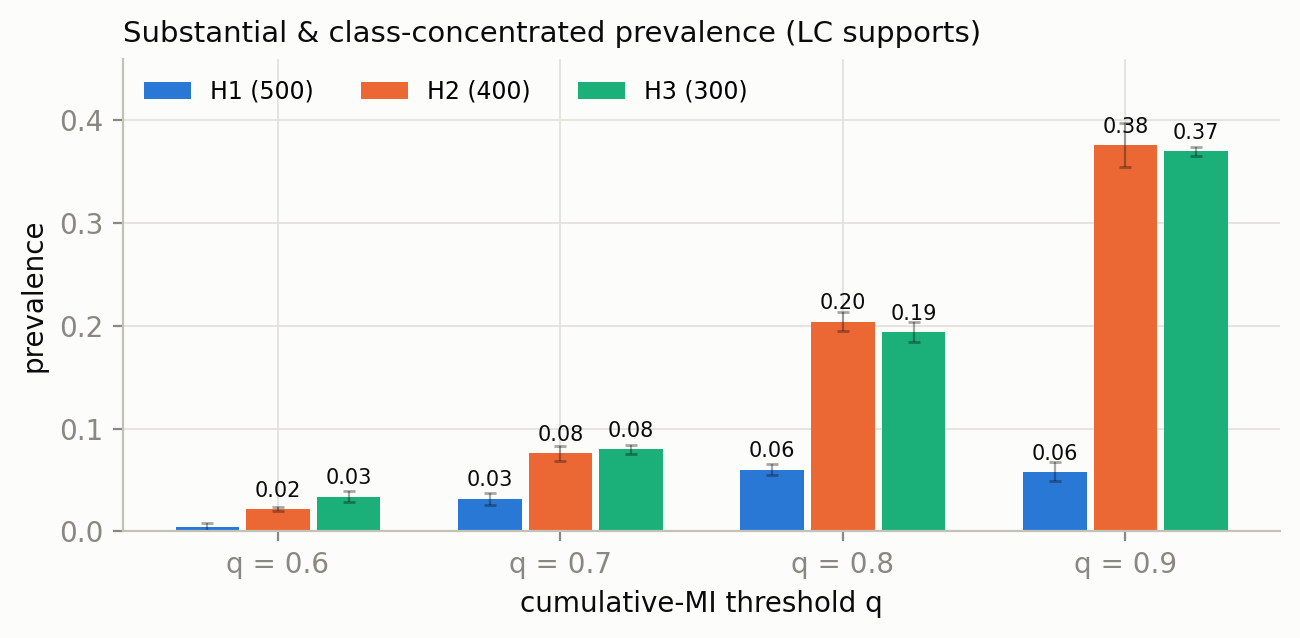

In [14]:
import figures_exp4 as fx
fx._rc()
for path in fx.main():
    pass
from IPython.display import Image, display
for p in sorted((HERE / "figures").glob("fig0*.png")):
    print(p.name)
# show the first figure inline
display(Image(filename=str(HERE / "figures" / "fig01_prevalence_by_layer_threshold.png")))